# Exame B – Previsão da Demanda de Bicicletas Compartilhadas em Seul

---

## Resumo Inicial e Objetivos do Trabalho

Este projeto aborda o desafio de investigar um conjunto de dados sobre o sistema público de bicicletas compartilhadas de Seul, na Coreia do Sul, cobrindo o período de dezembro de 2017 a novembro de 2018. O objetivo final é desenvolver um modelo preditivo capaz de estimar a quantidade de bicicletas alugadas em uma determinada hora (`Rented_Bike_Count`), combinando variáveis meteorológicas e fatores de calendário.

### Estrutura das Etapas:
1. **Etapa 1 – Análise Exploratória de Dados (EDA):** Compreensão aprofundada da distribuição das variáveis, identificação de anomalias/outliers, tratamento de inconsistências e análise preliminar de correlações e relações com a demanda.
2. **Etapa 2 – Testes de Hipótese:** Formulação de hipóteses estatísticas rigorosas para validar relações observadas na etapa exploratória.
3. **Etapa 3 – Modelagem Preditiva:** Ajuste de regressão linear múltipla, análise de resíduos, testes ANOVA e implementação de função de inferência para dados de teste cego.

> **Repositório de Referência:** [glaucogoncalves/p-e/exame-b-bike-sharing](https://github.com/glaucogoncalves/p-e/tree/main/exames/exame-b-bike-sharing)


## Seção 1 – Configuração do Ambiente e Reprodutibilidade

Para assegurar a reprodutibilidade dos resultados em conformidade com as diretrizes do exame, fixamos a semente pseudoaleatória global (`random_state = 2025`) e registramos formalmente as versões das principais bibliotecas utilizadas.


In [1]:
# Objetivo: Importar as bibliotecas essenciais, configurar a reprodutibilidade e exibir as versões
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 2025
print(f"Versões em uso:")
print(f" - pandas:      {pd.__version__}")
print(f" - numpy:       {np.__version__}")
print(f" - scikit-learn: {sklearn.__version__}")

Versões em uso:
 - pandas:      3.1.1
 - numpy:       2.5.4
 - scikit-learn: 1.9.1


## Seção 2 – Dicionário de Dados e Visão Geral

O dataset reúne registros horários do sistema público de bicicletas de Seul com informações meteorológicas e de calendário.

- **Período coberto:** 01/12/2017 a 30/11/2018 (7.008 registros horários).
- **Total de variáveis:** 14 variáveis (1 alvo, 2 temporais/identificação, 8 numéricas meteorológicas e 3 categóricas de calendário).

---

### Variáveis de Tempo e Identificação
| Nome da Variável | Descrição | Tipo |
| :--- | :--- | :--- |
| `Date` | Data do registro (`DD/MM/AAAA`). | Data (Texto) |
| `Hour` | Hora do dia do registro (0 a 23). | Numérica (Discreta) |

> *Nota:* A coluna `Date` serve de base para extração de atributos temporais e ordenação cronológica, não devendo ser utilizada de forma bruta na modelagem.

---

### Variável Dependente (Alvo)
| Nome da Variável | Descrição | Faixa / Estatísticas | Tipo |
| :--- | :--- | :--- | :--- |
| `Rented_Bike_Count` | Quantidade de bicicletas alugadas naquela hora. | Min: 0 \| Max: 3.556 \| Média: 704,97 \| Mediana: 504,5 | Numérica (Discreta) |

---

### Variáveis Preditoras Meteorológicas
| Nome da Variável | Descrição | Unidade | Tipo |
| :--- | :--- | :--- | :--- |
| `Temperature` | Temperatura do ar (-17,8 a 39,4 °C, média 12,91). | °C | Numérica Contínua |
| `Humidity` | Umidade relativa do ar (0 a 98%, média 58,27). | % | Numérica Contínua |
| `Wind_Speed` | Velocidade do vento (0 a 7,4 m/s, média 1,73). | m/s | Numérica Contínua |
| `Visibility` | Visibilidade horizontal (27 a 2.000, média 1.434,96). | 10 m | Numérica Discreta |
| `Dew_Point_Temperature` | Temperatura do ponto de orvalho (-30,6 a 26,8 °C). | °C | Numérica Contínua |
| `Solar_Radiation` | Radiação solar incidente (0 a 3,52 MJ/m²). | MJ/m² | Numérica Contínua |
| `Rainfall` | Volume de precipitação pluviométrica na hora (0 a 29,5 mm). | mm | Numérica Contínua |
| `Snowfall` | Volume de precipitação de neve na hora (0 a 8,8 cm). | cm | Numérica Contínua |

---

### Variáveis Preditoras de Calendário
| Nome da Variável | Descrição | Categorias e Contagens | Tipo |
| :--- | :--- | :--- | :--- |
| `Seasons` | Estação do ano. | `Spring` (1.766), `Summer` (1.767), `Autumn` (1.747), `Winter` (1.728) | Categórica (Nominal) |
| `Holiday` | Indicação de feriado. | `No Holiday` (6.660), `Holiday` (348) | Categórica (Binária) |
| `Functioning_Day` | Funcionamento do sistema naquele dia. | `Yes` (6.774), `No` (234) | Categórica (Binária) |


## Seção 3 – Carga e Inspeção Inicial dos Dados

Realizamos a importação direta do arquivo `bike_sharing.csv` e a verificação estrutural (tipos de dados e contagem de registros não nulos).


In [2]:
# Objetivo: Carregar o conjunto de dados oficial a partir do repositório da disciplina
df = pd.read_csv("https://raw.githubusercontent.com/glaucogoncalves/p-e/refs/heads/main/exames/exame-b-bike-sharing/bike_sharing.csv")

In [3]:
# Objetivo: Inspecionar os tipos primitivos de dados, dimensões e contagem de valores nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   7008 non-null   str    
 1   Rented_Bike_Count      7008 non-null   int64  
 2   Hour                   7008 non-null   int64  
 3   Temperature            7008 non-null   float64
 4   Humidity               7008 non-null   int64  
 5   Wind_Speed             7008 non-null   float64
 6   Visibility             7008 non-null   int64  
 7   Dew_Point_Temperature  7008 non-null   float64
 8   Solar_Radiation        7008 non-null   float64
 9   Rainfall               7008 non-null   float64
 10  Snowfall               7008 non-null   float64
 11  Seasons                7008 non-null   str    
 12  Holiday                7008 non-null   str    
 13  Functioning_Day        7008 non-null   str    
dtypes: float64(6), int64(4), str(4)
memory usage: 766.6 KB


### Justificativa – Conversão e Ordenação Temporal da Coluna `Date`

> **Raciocínio Investigativo:** A coluna `Date` vem originalmente tipada como texto (`object`) no formato `DD/MM/AAAA`. Ordenar diretamente por texto causaria uma ordenação lexicográfica e não temporal cronológica, inviabilizando qualquer análise de série temporal diária.
>
> **Tratamento Realizado:** Criou-se a variável `Date_Parsed` convertida para o tipo datetime (`pd.to_datetime`), permitindo ordenar os registros cronologicamente do primeiro ao último dia da coleta.


In [4]:
# Objetivo: Converter a coluna Date para datetime no formato DD/MM/AAAA e ordenar os dados cronologicamente
df['Date_Parsed'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df = df.sort_values(by="Date_Parsed").reset_index(drop=True)
df[['Date', 'Date_Parsed', 'Hour', 'Rented_Bike_Count']].head()

,Date,Date_Parsed,Hour,Rented_Bike_Count
0,01/12/2017,2017-12-01,9,490
1,01/12/2017,2017-12-01,21,405
2,01/12/2017,2017-12-01,13,451
3,01/12/2017,2017-12-01,7,460
4,01/12/2017,2017-12-01,5,100


## Seção 4 – Análise Exploratória: Fatores de Calendário e Sazonalidade

### Formulação da Intuição e Hipóteses Iniciais

> **Pergunta norteadora:** *Por que uma pessoa decide alugar uma bicicleta compartilhada em determinado horário ou dia?*
> 
> Dois grandes eixos intuitivos determinam esse comportamento:
> 1. **Fatores Temporais / Calendário:** Estações do ano, feriados, dias da semana e funcionamento do sistema.
> 2. **Fatores Meteorológicos / Conforto:** Temperatura, chuva, umidade, vento e radiação solar.
> 
> Iniciamos a exploração investigando os **fatores de calendário e sazonalidade** para compreender a dinâmica macro da demanda ao longo do tempo.


In [5]:
# Objetivo: Gerar o resumo estatístico das variáveis numéricas do conjunto de dados
df.describe()

,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,Dew_Point_Temperature,Solar_Radiation,Rainfall,Snowfall,Date_Parsed
count,7008.000000,7008.000000,7008.000000,7008.000000,7008.000000,7008.000000,7008.000000,7008.000000,7008.000000,7008.000000,7008
mean,704.974315,11.505565,12.913413,58.266124,1.729894,1434.956193,4.115411,0.573182,0.137728,0.078082,2018-06-01 01:02:15.616438
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,2017-12-01 00:00:00
25%,195.000000,6.000000,3.500000,43.000000,0.975000,935.750000,-4.500000,0.000000,0.000000,0.000000,2018-03-02 00:00:00
50%,504.500000,11.000000,13.900000,57.000000,1.500000,1690.000000,5.100000,0.010000,0.000000,0.000000,2018-06-01 00:00:00
75%,1066.000000,17.000000,22.500000,74.000000,2.300000,2000.000000,14.900000,0.930000,0.000000,0.000000,2018-08-31 00:00:00
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,26.800000,3.520000,29.500000,8.800000,2018-11-30 00:00:00
std,643.821404,6.910752,11.943094,20.251060,1.038611,608.915771,13.076265,0.872598,1.014356,0.446350,NaN


### 4.1 Sazonalidade e Comportamento por Estação do Ano (`Seasons`)

Para garantir uniformidade visual e comparabilidade em todos os gráficos temporais, definimos uma paleta de cores consistente para as quatro estações.


In [6]:
# Objetivo: Definir uma paleta de cores fixa por estação para padronização visual
fixed_season_palette = {
    'Summer': '#440154',  # Roxo escuro
    'Autumn': '#31688e',  # Azul/Verde escuro
    'Spring': '#21918c',  # Verde azulado
    'Winter': '#7ad151'   # Verde claro
}

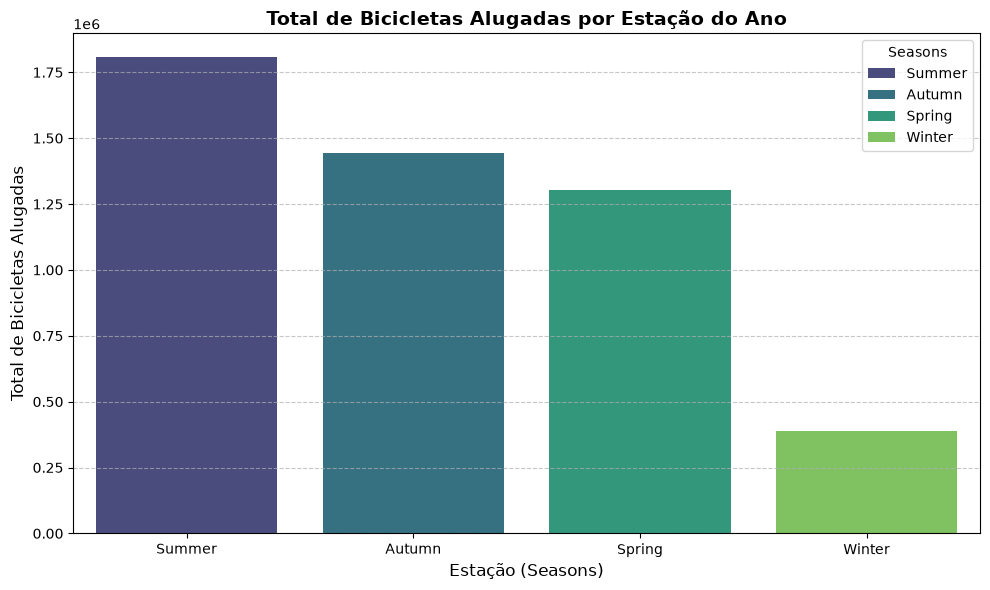

In [7]:
# Objetivo: Visualizar o total acumulado de bicicletas alugadas por estação do ano
bikes_by_season = df.groupby('Seasons')['Rented_Bike_Count'].sum().reset_index()
bikes_by_season = bikes_by_season.sort_values(by='Rented_Bike_Count', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Seasons',
    y='Rented_Bike_Count',
    data=bikes_by_season,
    palette='viridis',
    hue='Seasons',
    hue_order=['Summer', 'Autumn', 'Spring', 'Winter'],
    legend=True
)

plt.title('Total de Bicicletas Alugadas por Estação do Ano', fontsize=14, fontweight='bold')
plt.xlabel('Estação (Seasons)', fontsize=12)
plt.ylabel('Total de Bicicletas Alugadas', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

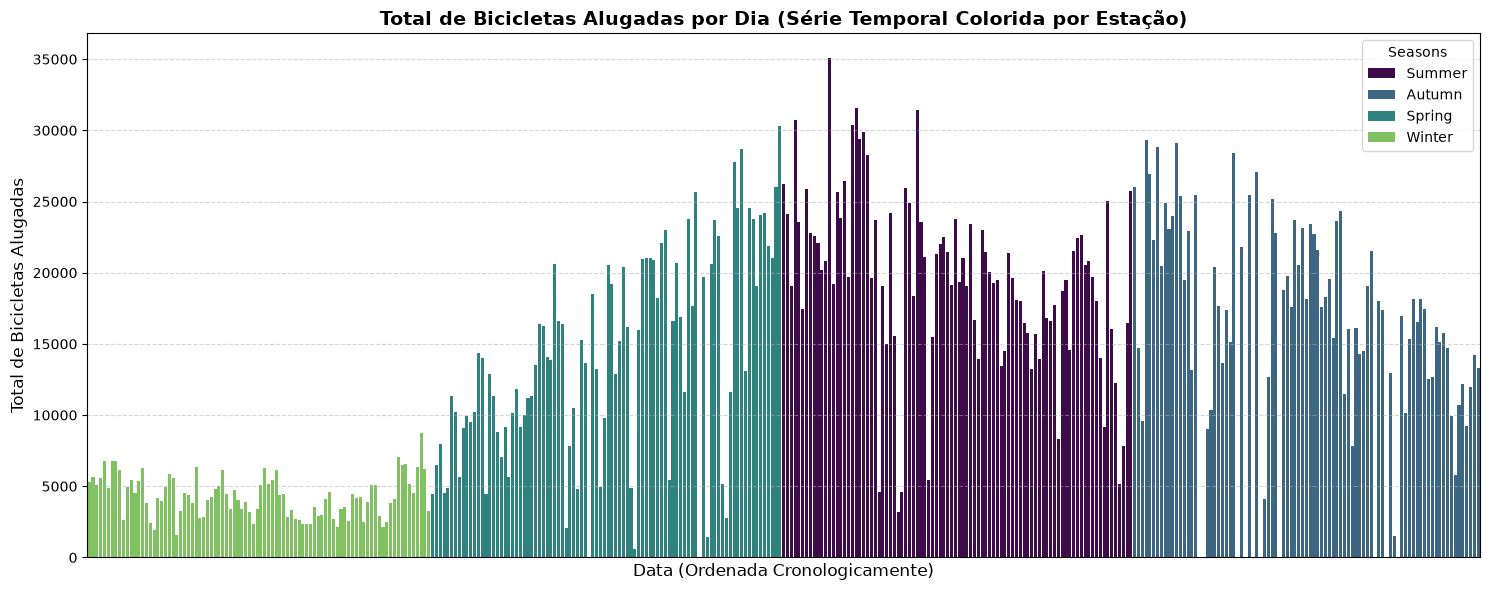

In [8]:
# Objetivo: Exibir a série temporal diária completa de aluguéis, colorida pela estação do ano
bikes_daily_season = df.groupby(['Date_Parsed', 'Seasons'])['Rented_Bike_Count'].sum().reset_index()
bikes_daily_season = bikes_daily_season.sort_values(by='Date_Parsed')

plt.figure(figsize=(15, 6))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Seasons',
    hue_order=['Summer', 'Autumn', 'Spring', 'Winter'],
    data=bikes_daily_season,
    dodge=False,
    palette=fixed_season_palette
)

plt.title('Total de Bicicletas Alugadas por Dia (Série Temporal Colorida por Estação)', fontsize=14, fontweight='bold')
plt.xlabel('Data (Ordenada Cronologicamente)', fontsize=12)
plt.ylabel('Total de Bicicletas Alugadas', fontsize=12)
plt.xticks([])  # Oculta rótulos individuais diários para evitar sobreposição
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Interpretação dos Resultados da Sazonalidade

> **Observação do aluno:**
> - O gráfico mostra que o volume de aluguéis no **inverno (`Winter`)** é drasticamente inferior ao das demais estações. Andar de bicicleta no frio rigoroso de Seul é naturalmente desconfortável.
> - Na série temporal ordenada cronologicamente, nota-se uma tendência nítida de alta pós-inverno, com picos expressivos no verão e outono.
>
> **O ponto intrigante formulado:**
> - Mesmo durante os períodos quentes e favoráveis (primavera, verão e outono), existem dias isolados com **quedas abruptas de demanda**, aproximando-se dos níveis do inverno.
> - O que essas datas têm em comum? Seriam feriados prolongados, finais de semana ou paralisações do serviço?
> - Vamos aprofundar a investigação examinando primeiro os **feriados e datas comemorativas**.


### 4.2 Investigação de Feriados e Datas Comemorativas (`Holiday`)

Para enriquecer a análise, foi realizada uma pesquisa externa sobre o calendário oficial de feriados nacionais na Coreia do Sul (Seul) durante o período da coleta (dezembro/2017 a novembro/2018):

| Data | Nome do Feriado / Celebração |
| :--- | :--- |
| `25/12/2017` | Natal (성탄절) |
| `01/01/2018` | Ano-Novo (신정) |
| `15/02/2018` | Véspera de Seollal |
| `16/02/2018` | Seollal / Ano-Novo Lunar (설날) |
| `17/02/2018` | Dia seguinte ao Seollal |
| `01/03/2018` | Dia do Movimento de Independência (삼일절) |
| `05/05/2018` | Dia das Crianças (어린이날) |
| `07/05/2018` | Feriado substituto do Dia das Crianças |
| `22/05/2018` | Aniversário de Buda (부처님 오신 날) |
| `06/06/2018` | Dia Memorial (현충일) |
| `15/08/2018` | Dia da Libertação (광복절) |
| `23/09/2018` | Véspera de Chuseok |
| `24/09/2018` | Chuseok / Ação de Graças coreana (추석) |
| `25/09/2018` | Dia seguinte ao Chuseok |
| `26/09/2018` | Feriado substituto do Chuseok |
| `03/10/2018` | Dia da Fundação Nacional (개천절) |
| `09/10/2018` | Dia do Hangeul (한글날) |

*(Fonte do calendário sul-coreano: [time.is/calendar/2018/South_Korea](https://time.is/calendar/2018/South_Korea))*


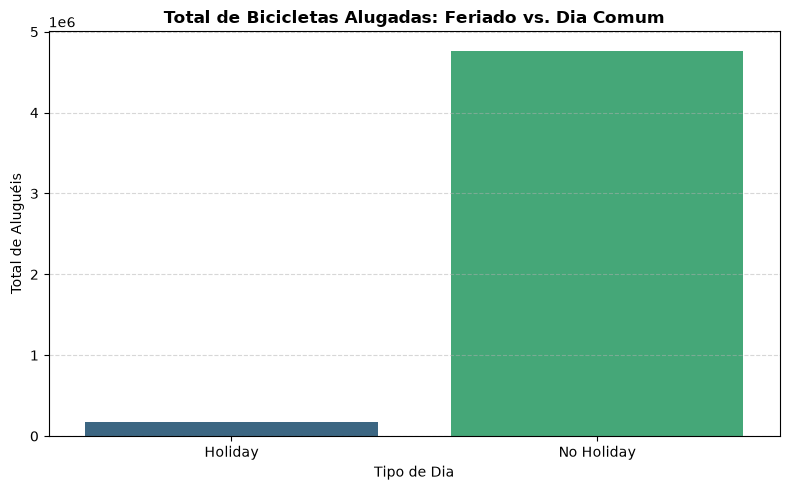

In [9]:
# Objetivo: Comparar o volume agregado de aluguéis entre dias de feriado e dias comuns
bikes_holiday_summary = df.groupby('Holiday')['Rented_Bike_Count'].sum().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x='Holiday',
    y='Rented_Bike_Count',
    data=bikes_holiday_summary,
    palette='viridis',
    hue='Holiday',
    legend=False
)
plt.title('Total de Bicicletas Alugadas: Feriado vs. Dia Comum', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Dia', fontsize=10)
plt.ylabel('Total de Aluguéis', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

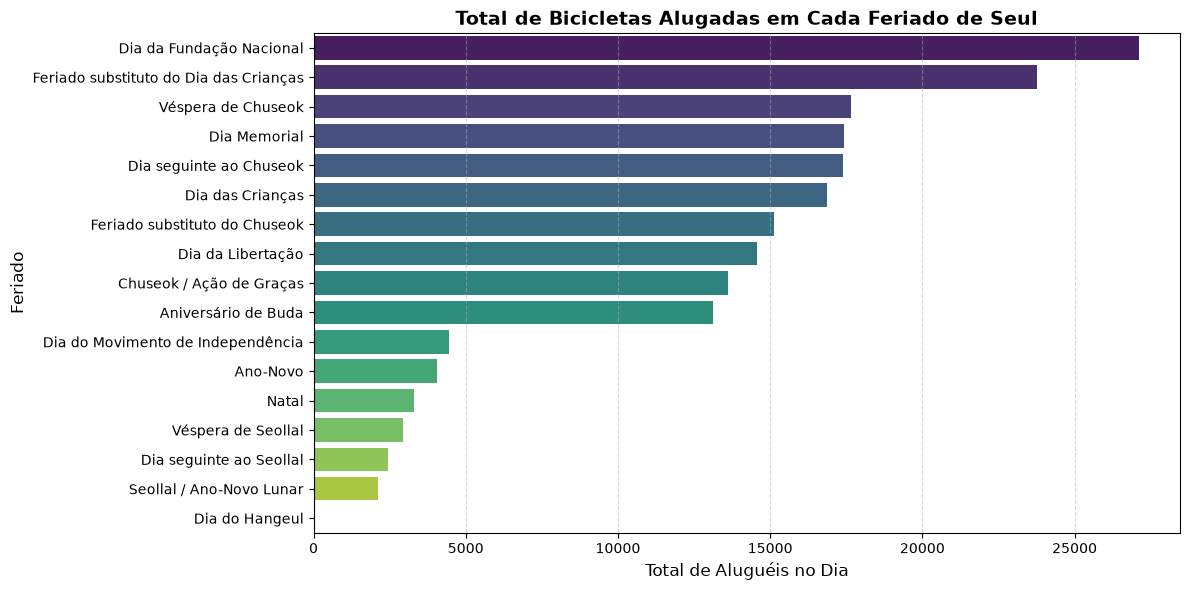

In [10]:
# Objetivo: Analisar individualmente a demanda de bicicletas em cada um dos feriados de Seul mapeados
feriados_mapeados = {
    '25/12/2017': 'Natal',
    '01/01/2018': 'Ano-Novo',
    '15/02/2018': 'Véspera de Seollal',
    '16/02/2018': 'Seollal / Ano-Novo Lunar',
    '17/02/2018': 'Dia seguinte ao Seollal',
    '01/03/2018': 'Dia do Movimento de Independência',
    '05/05/2018': 'Dia das Crianças',
    '07/05/2018': 'Feriado substituto do Dia das Crianças',
    '22/05/2018': 'Aniversário de Buda',
    '06/06/2018': 'Dia Memorial',
    '15/08/2018': 'Dia da Libertação',
    '23/09/2018': 'Véspera de Chuseok',
    '24/09/2018': 'Chuseok / Ação de Graças',
    '25/09/2018': 'Dia seguinte ao Chuseok',
    '26/09/2018': 'Feriado substituto do Chuseok',
    '03/10/2018': 'Dia da Fundação Nacional',
    '09/10/2018': 'Dia do Hangeul'
}

daily_rentals = df.groupby('Date')['Rented_Bike_Count'].sum().reset_index()
daily_rentals_holidays = daily_rentals[daily_rentals['Date'].isin(feriados_mapeados.keys())].copy()
daily_rentals_holidays['Nome_Feriado'] = daily_rentals_holidays['Date'].map(feriados_mapeados)
daily_rentals_holidays = daily_rentals_holidays.sort_values(by='Rented_Bike_Count', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x='Rented_Bike_Count',
    y='Nome_Feriado',
    data=daily_rentals_holidays,
    palette='viridis',
    hue='Nome_Feriado',
    legend=False
)
plt.title('Total de Bicicletas Alugadas em Cada Feriado de Seul', fontsize=14, fontweight='bold')
plt.xlabel('Total de Aluguéis no Dia', fontsize=12)
plt.ylabel('Feriado', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Interpretação dos Resultados dos Feriados

> **Reflexão analítica do aluno:**
> - O gráfico comparativo geral indica um total de aluguéis muito menor em feriados em relação a dias normais. No entanto, isso é um reflexo direto da desproporção na frequência das categorias: há apenas 348 registros de feriado contra 6.660 de dias normais no dataset.
> - Ao observar o gráfico específico por feriado, constata-se o oposto da intuição inicial: feriados registraram volumes expressivos de aluguel.
> - Conclusão parcial: **Os feriados em si não explicam as quedas drásticas de demanda observadas ao longo do ano.**
> - Próxima hipótese a testar: Será que os **dias da semana** (dias úteis vs. finais de semana) explicam esse comportamento?


### 4.3 Investigação de Dias Úteis vs. Finais de Semana (`Day_Type`)

### Justificativa da Criação das Features Temporais
> Criamos as variáveis derivadas `Day_of_Week` (0 = Segunda, ..., 6 = Domingo) e `Day_Type` (`Weekday` vs. `Weekend`) a partir de `Date_Parsed`. Essa engenharia de features visa verificar se o propósito de locomoção (trabalho/estudo em dias úteis versus lazer em finais de semana) causa variações acentuadas na demanda diária.


In [18]:
# Objetivo: Criar features para identificar o dia da semana e classificar em dia útil (Weekday) ou final de semana (Weekend)
df['Day_of_Week'] = df['Date_Parsed'].dt.day_of_week
df['Day_Type'] = df['Day_of_Week'].apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')

print("Distribuição dos registros horários por Tipo de Dia:")
print(df['Day_Type'].value_counts())
print("\nAmostra das variáveis temporais criadas:")
display(df[['Date_Parsed', 'Day_of_Week', 'Day_Type']].drop_duplicates().sort_values(by='Date_Parsed').head(7))

Distribuição dos registros horários por Tipo de Dia:
Day_Type
Weekday    4995
Weekend    2013
Name: count, dtype: int64

Amostra das variáveis temporais criadas:


,Date_Parsed,Day_of_Week,Day_Type
0,2017-12-01,4,Weekday
15,2017-12-02,5,Weekend
29,2017-12-03,6,Weekend
47,2017-12-04,0,Weekday
63,2017-12-05,1,Weekday
83,2017-12-06,2,Weekday
100,2017-12-07,3,Weekday


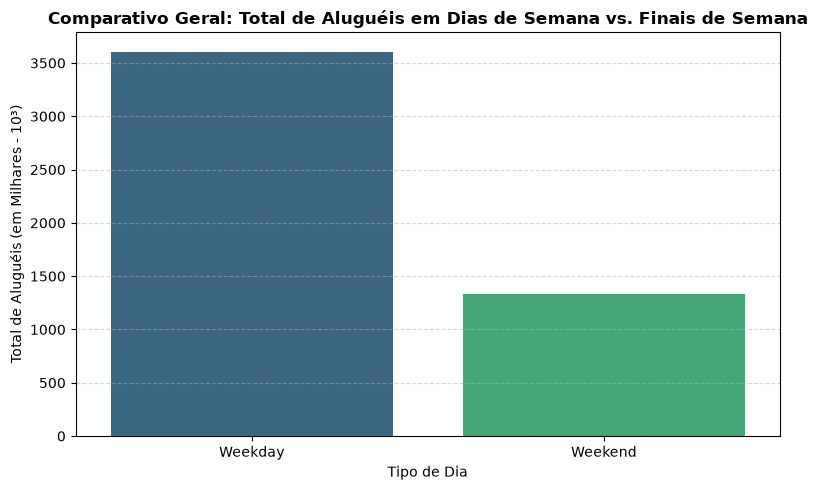

In [12]:
# Objetivo: Comparar o total acumulado de aluguéis entre dias de semana e finais de semana
total_by_day_type = df.groupby('Day_Type')['Rented_Bike_Count'].sum().reset_index()
total_by_day_type['Total_K'] = total_by_day_type['Rented_Bike_Count'] / 1000

plt.figure(figsize=(8, 5))
sns.barplot(
    x='Day_Type',
    y='Total_K',
    data=total_by_day_type,
    palette='viridis',
    hue='Day_Type',
    legend=False
)
plt.title('Comparativo Geral: Total de Aluguéis em Dias de Semana vs. Finais de Semana', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Dia', fontsize=10)
plt.ylabel('Total de Aluguéis (em Milhares - 10³)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

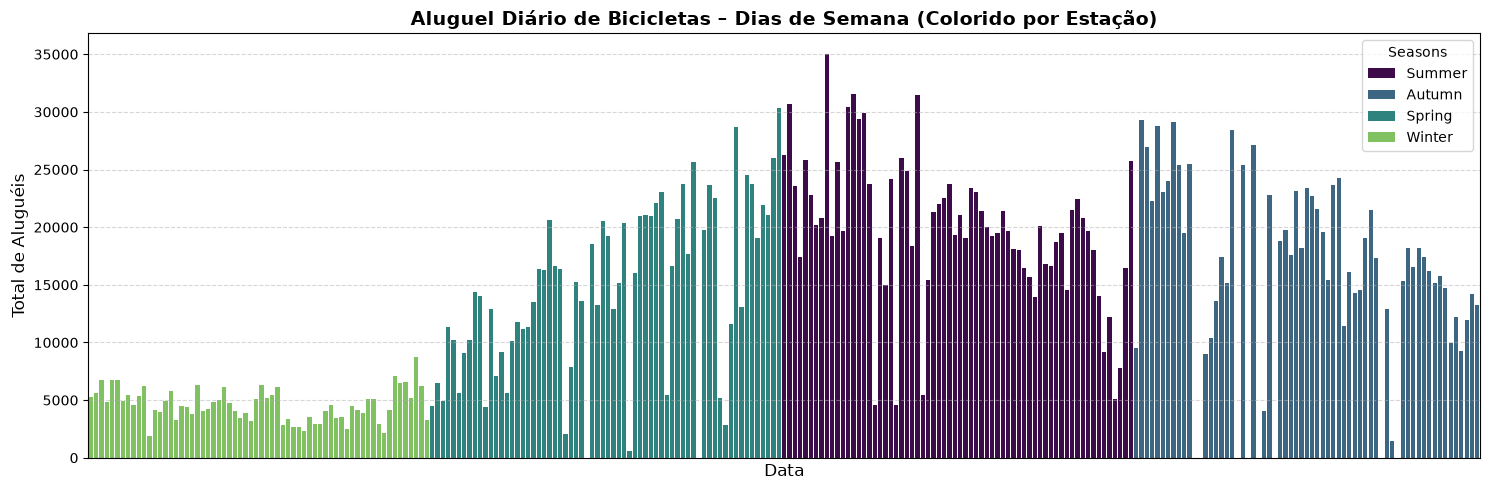

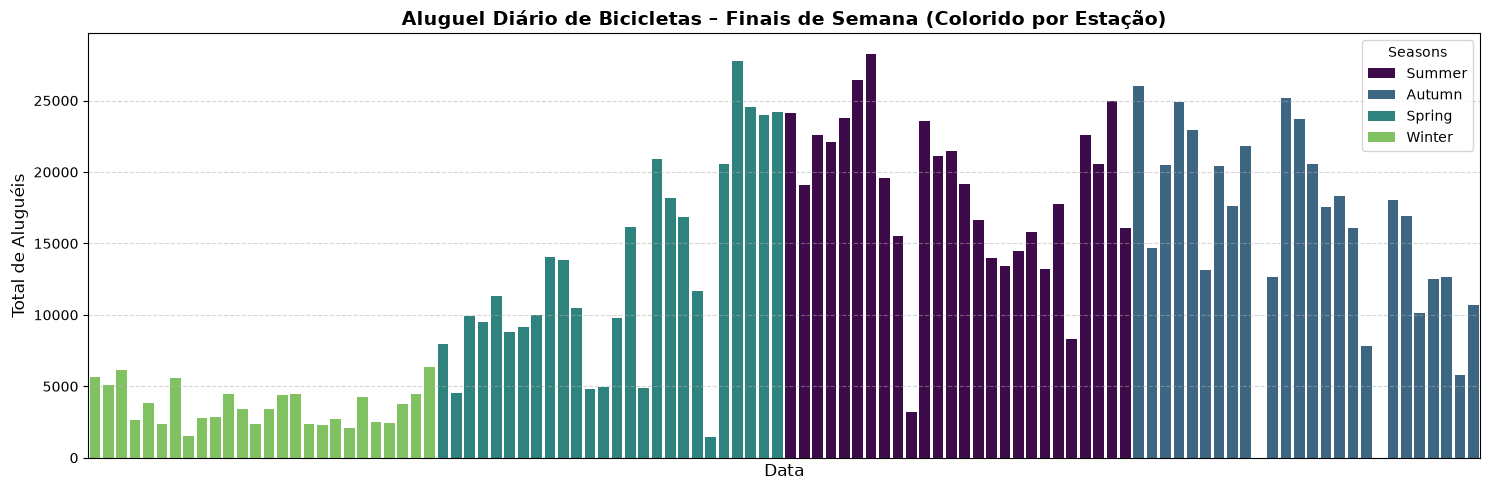

In [13]:
# Objetivo: Comparar a série temporal de dias de semana versus finais de semana separadamente
daily_summary = df.groupby(['Date_Parsed', 'Day_Type', 'Seasons'])['Rented_Bike_Count'].sum().reset_index()

weekdays_data = daily_summary[daily_summary['Day_Type'] == 'Weekday'].sort_values(by='Date_Parsed')
weekends_data = daily_summary[daily_summary['Day_Type'] == 'Weekend'].sort_values(by='Date_Parsed')

plt.figure(figsize=(15, 5))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Seasons',
    hue_order=['Summer', 'Autumn', 'Spring', 'Winter'],
    data=weekdays_data,
    dodge=False,
    palette=fixed_season_palette
)
plt.title('Aluguel Diário de Bicicletas – Dias de Semana (Colorido por Estação)', fontsize=14, fontweight='bold')
plt.xlabel('Data', fontsize=12)
plt.ylabel('Total de Aluguéis', fontsize=12)
plt.xticks([])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Seasons',
    hue_order=['Summer', 'Autumn', 'Spring', 'Winter'],
    data=weekends_data,
    dodge=False,
    palette=fixed_season_palette
)
plt.title('Aluguel Diário de Bicicletas – Finais de Semana (Colorido por Estação)', fontsize=14, fontweight='bold')
plt.xlabel('Data', fontsize=12)
plt.ylabel('Total de Aluguéis', fontsize=12)
plt.xticks([])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

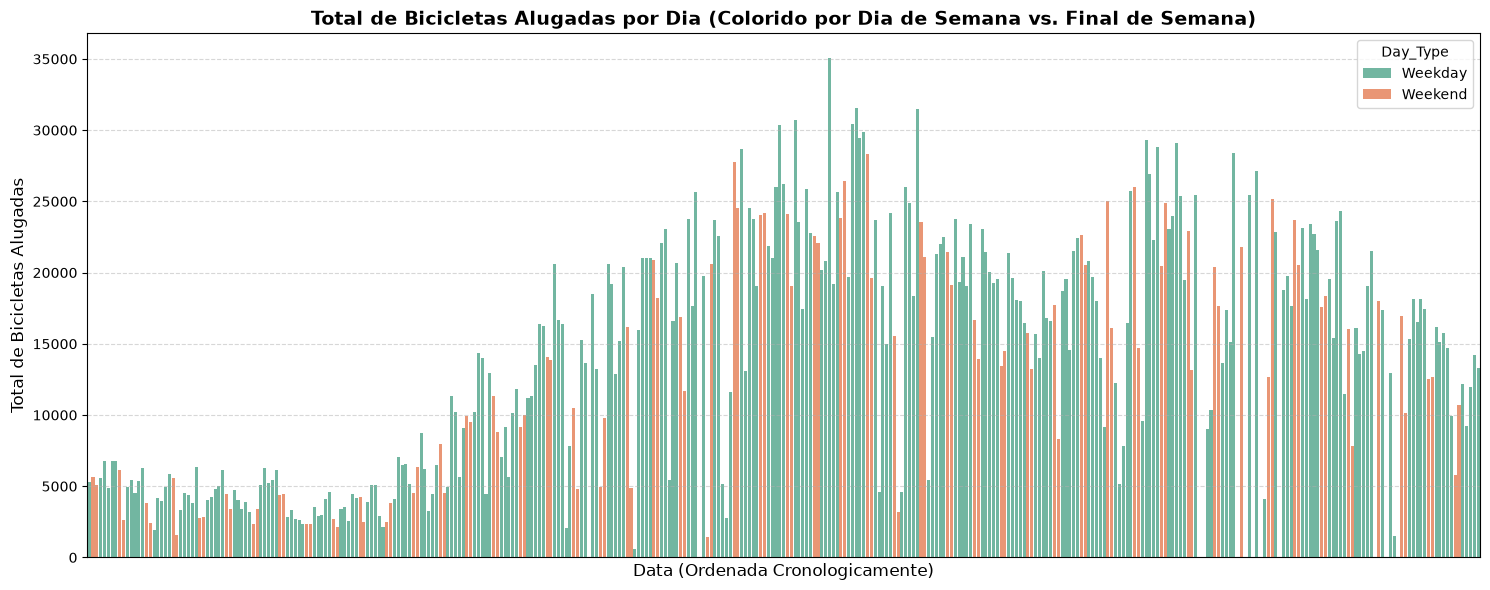

In [14]:
# Objetivo: Exibir a série temporal diária completa distinguindo dias de semana e finais de semana
bikes_daily_daytype = df.groupby(['Date_Parsed', 'Day_Type'])['Rented_Bike_Count'].sum().reset_index()
bikes_daily_daytype = bikes_daily_daytype.sort_values(by='Date_Parsed')

plt.figure(figsize=(15, 6))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Day_Type',
    hue_order=['Weekday', 'Weekend'],
    data=bikes_daily_daytype,
    dodge=False,
    palette='Set2'
)

plt.title('Total de Bicicletas Alugadas por Dia (Colorido por Dia de Semana vs. Final de Semana)', fontsize=14, fontweight='bold')
plt.xlabel('Data (Ordenada Cronologicamente)', fontsize=12)
plt.ylabel('Total de Bicicletas Alugadas', fontsize=12)
plt.xticks([])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Interpretação dos Resultados do Tipo de Dia

> **Síntese da investigação do aluno:**
> - O comparativo temporal deixa claro que **não é o dia da semana isolado que explica as quedas bruscas de aluguel**.
> - Tanto em dias úteis quanto em finais de semana, a curva temporal acompanha tendências similares e apresenta vales pronunciados nos mesmos períodos.
> - Conclusão intermediária: Fatores puramente de calendário (se é feriado ou se é final de semana) não são a causa primária das anomalias de baixa demanda.
> - Resta um fator operacional crítico do calendário a ser investigado: **o funcionamento do sistema (`Functioning_Day`)**.


### 4.4 Status de Operação do Sistema (`Functioning_Day`)

Investigamos se os dias com quedas atípicas de demanda decorrem de paralisações operacionais do próprio sistema de compartilhamento.


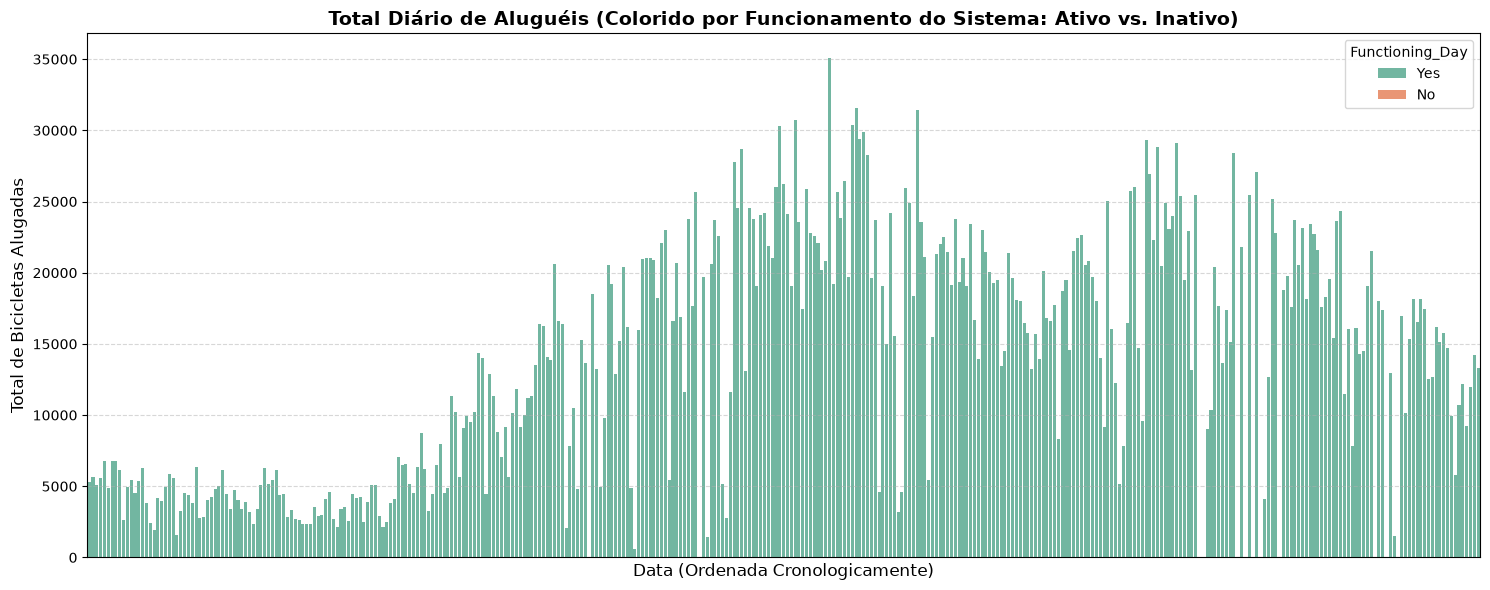

In [15]:
# Objetivo: Visualizar a série temporal de aluguéis destacando dias com sistema ativo versus inativo
bikes_daily_functioning = df.groupby(['Date_Parsed', 'Functioning_Day'])['Rented_Bike_Count'].sum().reset_index()
bikes_daily_functioning = bikes_daily_functioning.sort_values(by='Date_Parsed')

plt.figure(figsize=(15, 6))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Functioning_Day',
    hue_order=['Yes', 'No'],
    data=bikes_daily_functioning,
    dodge=False,
    palette='Set2'
)

plt.title('Total Diário de Aluguéis (Colorido por Funcionamento do Sistema: Ativo vs. Inativo)', fontsize=14, fontweight='bold')
plt.xlabel('Data (Ordenada Cronologicamente)', fontsize=12)
plt.ylabel('Total de Bicicletas Alugadas', fontsize=12)
plt.xticks([])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [16]:
# Objetivo: Inspecionar os registros onde o sistema esteve inativo (Functioning_Day == 'No')
dias_inativos = bikes_daily_functioning[bikes_daily_functioning["Functioning_Day"] == "No"]
print(f"Total de datas com registro de inatividade: {len(dias_inativos)}")
dias_inativos

Total de datas com registro de inatividade: 13


,Date_Parsed,Functioning_Day,Rented_Bike_Count
131,2018-04-11,No,0
160,2018-05-10,No,0
291,2018-09-18,No,0
292,2018-09-19,No,0
301,2018-09-28,No,0
303,2018-09-30,No,0
305,2018-10-02,No,0
307,2018-10-04,No,0
309,2018-10-06,No,0
313,2018-10-09,No,0


### Conclusão Parcial e Transição para as Variáveis Numéricas

> **Constatação fundamental do aluno:**
> - Conforme suspeitado, em todos os dias em que o sistema esteve inativo (`Functioning_Day == 'No'`), a contagem de aluguéis é **estritamente zero** (`Rented_Bike_Count == 0`). Isso explica completamente diversos pontos nulos identificados na série temporal.
>
> **Próxima etapa investigativa:**
> - Com o funcionamento do sistema esclarecido e os fatores de calendário delimitados, a questão central agora é: **o que faz a demanda despencar em dias normais de funcionamento (`Functioning_Day == 'Yes'`), inclusive durante as estações quentes?**
> - A resposta provável reside nas **variáveis numéricas e meteorológicas** (temperaturas extremas, chuva torrencial, neve intensa, vento e umidade elevada).
> - Seguiremos a exploração com a análise detalhada das variáveis contínuas e sua correlação com `Rented_Bike_Count`.
